In [30]:
import pandas as pd
import numpy as np
import os
import sys
import pandas as pd
pd.options.mode.chained_assignment = None  # 完全关闭警告
import warnings
warnings.filterwarnings('ignore', category=pd.errors.SettingWithCopyWarning)


In [31]:

stead=pd.read_csv('/home/cloudlab/Code_DL/DEEP_STEAD_PYTORCH/Pytorch_STEAD/DATA/Texd.csv')

eqt=pd.read_csv('/home/yuan/code/SeisMoE/data/TEXD_Predict/TEXD_EQTransformer_Predict/picks_moe2.csv')

moe=pd.read_csv('/home/yuan/code/SeisMoE/data/TEXD_Predict/TEXD_Moe_Predict/picks_moe2.csv')

phasenet=pd.read_csv('/home/yuan/code/SeisMoE/data/TEXD_Predict/TEXD_PhaseNet_Predict/picks_moe2.csv')

ration=0.03
random_set=36

/tmp/ipykernel_2029556/230572216.py:1: DtypeWarning: Columns (7,10,12,21,22) have mixed types. Specify dtype option on import or set low_memory=False.
  stead=pd.read_csv('/home/cloudlab/Code_DL/DEEP_STEAD_PYTORCH/Pytorch_STEAD/DATA/Texd.csv')


In [32]:
sampled_data = stead.sample(frac=ration, random_state=random_set)
sampled_data_count=len(stead.sample(frac=ration, random_state=random_set))
noise_count = len(sampled_data[sampled_data['trace_category'] == 'noise'])
earthquake_count=sampled_data_count - noise_count
print(f"noise_count:{noise_count}")
print(f"earthquake_count:{earthquake_count}")

noise_count:6297
earthquake_count:9294


# EQT

In [33]:


# 提取 eqt 中的 file_name
file_names = eqt['trace_name']

# 筛选 stead 中 trace_name 与 file_name 匹配的行
filtered_stead = stead[stead['trace_name'].isin(file_names)]



# 合并两个数据框，基于 file_name 和 trace_name 的匹配
merged = pd.merge(eqt, filtered_stead, left_on='trace_name', right_on='trace_name')


# 计算时间差（向量化操作）
merged['p_error'] = (merged['trace_p_arrival_sample'] - merged['p_idx'])
merged['s_error'] = (merged['trace_s_arrival_sample'] - merged['s_idx'])


# 选择需要的列
result_eqt = merged[['trace_name','trace_category', 'trace_p_arrival_sample','trace_s_arrival_sample','p_idx','s_idx','p_error','s_error']]
# 将结果保存到 CSV 文件

result_eqt

,trace_name,trace_category,trace_p_arrival_sample,trace_s_arrival_sample,p_idx,s_idx,p_error,s_error
0,"bucket454$1004,:3,:6000",earthquake_local,580.0,861.0,597,850.0,-17.0,11.0
1,"bucket359$715,:3,:6000",earthquake_local,618.0,731.0,616,730.0,2.0,1.0
2,"bucket369$93,:3,:6000",earthquake_local,489.0,641.0,495,640.0,-6.0,1.0
3,"bucket437$624,:3,:6000",earthquake_local,269.0,560.0,273,556.0,-4.0,4.0
4,"bucket431$547,:3,:6000",earthquake_local,621.0,1309.0,700,1292.0,-79.0,17.0
...,...,...,...,...,...,...,...,...
8079,"bucket495$847,:3,:6000",earthquake_local,777.0,1402.0,799,1414.0,-22.0,-12.0
8080,"bucket436$439,:3,:6000",earthquake_local,698.0,1153.0,714,1160.0,-16.0,-7.0
8081,"bucket336$524,:3,:6000",earthquake_local,262.0,447.0,271,456.0,-9.0,-9.0
8082,"bucket414$327,:3,:6000",earthquake_local,972.0,1626.0,999,1657.0,-27.0,-31.0


In [34]:
#计算TP，FP，FN设置TP阈值为50个点
TP_threshold_TP = 50
TP_threshold_FN= 50
result_eqt.loc[:, 'p_TP'] = np.where(abs(result_eqt['p_error']) <= TP_threshold_TP, 1, 0)
result_eqt.loc[:, 's_TP'] = np.where(abs(result_eqt['s_error']) <= TP_threshold_TP, 1, 0)

#FN表示大于0.5
result_eqt.loc[:, 'p_FN'] = np.where(abs(result_eqt['p_error']) > TP_threshold_FN, 1, 0)
result_eqt.loc[:, 's_FN'] = np.where(abs(result_eqt['s_error']) > TP_threshold_FN, 1, 0)

#FP表示trace_name里面含有噪声的数量，也就是trace_name列是noise的数量
result_eqt.loc[:, 'p_FP'] = np.where(result_eqt['trace_category'] == 'noise', 1, 0)
result_eqt.loc[:, 's_FP'] = np.where(result_eqt['trace_category'] == 'noise', 1, 0)

#计算stead的随机种子样本的noise个数
sampled_data = stead.sample(frac=ration, random_state=random_set)
sampled_data_count=len(stead.sample(frac=ration, random_state=random_set))
noise_count = len(sampled_data[sampled_data['trace_category'] == 'noise'])
earthquake_count=sampled_data_count - noise_count


#FP：噪声误报 + 未检测到的地震事件（除开噪声）
p_FP_count=result_eqt.loc[:, 'p_FP'].sum()+ earthquake_count - result_eqt.loc[:, 'p_TP'].sum() - result_eqt.loc[:, 'p_FN'].sum()
s_FP_count=result_eqt.loc[:, 's_FP'].sum()+ earthquake_count - result_eqt.loc[:, 's_TP'].sum() - result_eqt.loc[:, 's_FN'].sum()
#计算precision，recall，f1
p_TP= result_eqt['p_TP'].sum()
s_TP= result_eqt['s_TP'].sum()

p_FN= result_eqt['p_FN'].sum()
s_FN= result_eqt['s_FN'].sum()

# p_TP,p_FN = p_FN,p_TP
# s_TP,s_FN = s_FN,s_TP


# 计算precision，recall，f1
p_precision = p_TP / (p_TP + p_FP_count) if (p_TP + p_FP_count) > 0 else 0
s_precision = s_TP / (s_TP + s_FP_count) if (s_TP + s_FP_count) > 0 else 0

p_recall = p_TP / (p_TP + p_FN) if (p_TP + p_FN) > 0 else 0
s_recall = s_TP / (s_TP + s_FN) if (s_TP + s_FN) > 0 else 0

p_f1 = 2 * (p_precision * p_recall) / (p_precision + p_recall) if (p_precision + p_recall) > 0 else 0
s_f1 = 2 * (s_precision * s_recall) / (s_precision + s_recall) if (s_precision + s_recall) > 0 else 0

#计算MAE，标准差
result_eqt.loc[:, 'p_TP_mae'] = np.where(result_eqt['p_TP'] == 1, result_eqt['p_error'], 0)
result_eqt.loc[:, 's_TP_mae'] = np.where(result_eqt['s_TP'] == 1, result_eqt['s_error'], 0)
# 计算 TP 的平均绝对误差
p_TP_mae = abs(result_eqt['p_TP_mae']).sum() / p_TP if p_TP > 0 else 0
s_TP_mae = abs(result_eqt['s_TP_mae']).sum() / s_TP if s_TP > 0 else 0
#mae还需要除100，
p_TP_mae = p_TP_mae / 100
s_TP_mae = s_TP_mae / 100

#计算TP的标准差误差
p_TP_std = result_eqt['p_TP_mae'].std() / 100
s_TP_std = result_eqt['s_TP_mae'].std() / 100



print("P-TP:", p_TP)
print("P-FP:", p_FP_count)
print("P-FN:", p_FN)
print("P-Precision:", p_precision)
print("P-Recall:", p_recall)
print("P-F1 Score:", p_f1)
print("P-MAE:", p_TP_mae)
print("P-STD:", p_TP_std)

print("S-TP:", s_TP)
print("S-FP:", s_FP_count)
print("S-FN:", s_FN)
print("S-Precision:", s_precision)
print("S-Recall:", s_recall)
print("S-F1 Score:", s_f1)
print("S-MAE:", s_TP_mae)
print("S-STD:", s_TP_std)


#将结果做成一个表格
result_table_eqt = pd.DataFrame({
    'EQT': ['TP', 'FP', 'FN', 'Precision', 'Recall', 'F1 Score', 'MAE', 'STD'],
    'P': [p_TP, p_FP_count, p_FN, p_precision, p_recall, p_f1, p_TP_mae, p_TP_std],
    'S': [s_TP, s_FP_count, s_FN, s_precision, s_recall, s_f1, s_TP_mae, s_TP_std]
})


# 指定需要转换为整数的行
int_rows = ['TP', 'FP', 'FN']

# 对 'P' 和 'S' 列中符合条件的行转换为整数
result_table_eqt.loc[result_table_eqt['EQT'].isin(int_rows), ['P', 'S']] = (
    result_table_eqt.loc[result_table_eqt['EQT'].isin(int_rows), ['P', 'S']]
    .astype(int)  # 强制转换为整数
)


P-TP: 6558
P-FP: 1272
P-FN: 1495
P-Precision: 0.8375478927203065
P-Recall: 0.81435489879548
P-F1 Score: 0.8257885789838192
P-MAE: 0.17479871912168346
P-STD: 0.2006143160771776
S-TP: 6859
S-FP: 1344
S-FN: 1122
S-Precision: 0.836157503352432
S-Recall: 0.8594161132690139
S-F1 Score: 0.8476272862086011
S-MAE: 0.1059629683627351
S-STD: 0.13534430622816473


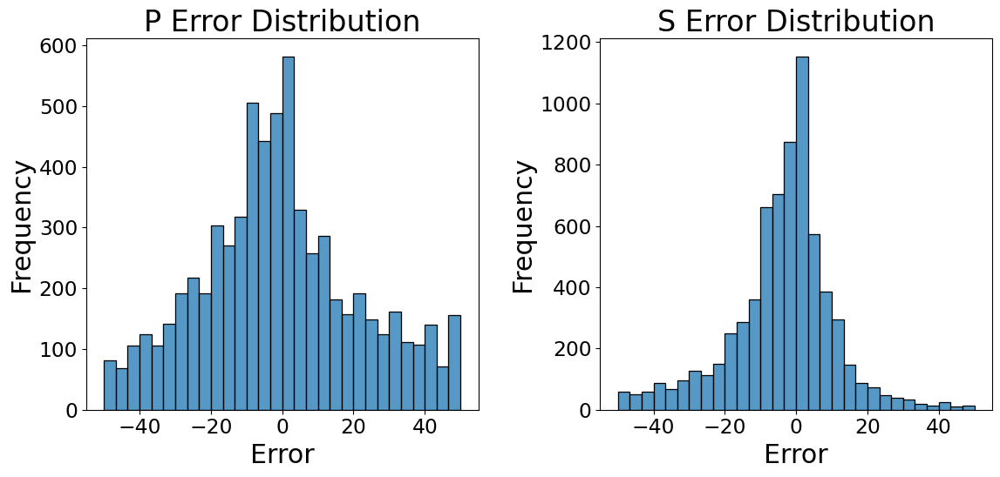

In [35]:


import matplotlib.pyplot as plt
import seaborn as sns

#绘制TP的误差图，x是误差，y是频率
#P,S分开绘图两张图，只需要绘制TP的部分
# 设置图形的大小
plt.figure(figsize=(12, 6))
# 绘制 P 的误差分布
plt.subplot(1, 2, 1)
sns.histplot(result_eqt[result_eqt['p_TP'] == 1]['p_error'], bins=30, kde=False)
plt.title('P Error Distribution')
plt.xlabel('Error')
plt.ylabel('Frequency')
# 绘制 S 的误差分布
plt.subplot(1, 2, 2)
sns.histplot(result_eqt[result_eqt['s_TP'] == 1]['s_error'], bins=30, kde=False)
plt.title('S Error Distribution')
plt.xlabel('Error')
plt.ylabel('Frequency')
# 显示图形
plt.tight_layout()
plt.show()

# MOE

In [36]:


# 提取 eqt 中的 file_name
file_names = moe['trace_name']

# 筛选 stead 中 trace_name 与 file_name 匹配的行
filtered_stead = stead[stead['trace_name'].isin(file_names)]



# 合并两个数据框，基于 file_name 和 trace_name 的匹配
merged = pd.merge(moe, filtered_stead, left_on='trace_name', right_on='trace_name')


# 计算时间差（向量化操作）
merged['p_error'] = (merged['trace_p_arrival_sample'] - merged['p_idx'])
merged['s_error'] = (merged['trace_s_arrival_sample'] - merged['s_idx'])


# 选择需要的列
result_moe = merged[['trace_name','trace_category', 'trace_p_arrival_sample','trace_s_arrival_sample','p_idx','s_idx','p_error','s_error']]
# 将结果保存到 CSV 文件

result_moe

,trace_name,trace_category,trace_p_arrival_sample,trace_s_arrival_sample,p_idx,s_idx,p_error,s_error
0,"bucket454$1004,:3,:6000",earthquake_local,580.0,861.0,588,846.0,-8.0,15.0
1,"bucket23$700,:3,:6000",noise,NaN,NaN,410,1351.0,NaN,NaN
2,"bucket359$715,:3,:6000",earthquake_local,618.0,731.0,612,722.0,6.0,9.0
3,"bucket369$93,:3,:6000",earthquake_local,489.0,641.0,491,631.0,-2.0,10.0
4,"bucket437$624,:3,:6000",earthquake_local,269.0,560.0,283,556.0,-14.0,4.0
...,...,...,...,...,...,...,...,...
8377,"bucket495$847,:3,:6000",earthquake_local,777.0,1402.0,797,1368.0,-20.0,34.0
8378,"bucket436$439,:3,:6000",earthquake_local,698.0,1153.0,800,1262.0,-102.0,-109.0
8379,"bucket336$524,:3,:6000",earthquake_local,262.0,447.0,276,451.0,-14.0,-4.0
8380,"bucket414$327,:3,:6000",earthquake_local,972.0,1626.0,1000,1640.0,-28.0,-14.0


In [37]:
name=result_moe[(result_moe['p_error'] == 0) & (result_moe['s_error'] ==0)]['trace_name']
stead[(stead['trace_name'].isin(name)) & (stead['source_magnitude']>=1)]
# stead[stead['source_magnitude']>=5]

,trace_coda_end_sample,source_depth_km,source_latitude_deg,source_longitude_deg,source_magnitude,source_origin_time,trace_p_arrival_sample,trace_p_arrival_time,trace_p_arrival_uncertainty_s,trace_s_arrival_sample,...,station_elevation_m,station_latitude_deg,station_longitude_deg,station_code,trace_category,trace_name_original,split,trace_name,trace_causal,trace_polarity
337251,4342.0,5.942505,32.287903,-101.806283,3.650859,2020-12-31T19:12:33.616120Z,202.0,2020-12-31T19:13:00.496407Z,0.2,2272.0,...,782.4,31.303087,-103.099701,PB19,earthquake_local,texnet2020zsiq_PB19_EV,train,"bucket328$512,:3,:6000",unknown,D
378108,1384.0,7.391260,31.673977,-104.411585,1.582994,2021-06-24T23:44:14.795541Z,950.0,2021-06-24T23:44:18.828216Z,0.1,1167.0,...,1139.0,31.774145,-104.301444,PB09,earthquake_local,texnet2021mhsn_PB09_EV,dev,"bucket369$840,:3,:6000",unknown,U
398176,1240.0,3.545939,32.212830,-103.098919,1.937358,2021-09-20T23:31:45.692482Z,850.0,2021-09-20T23:31:47.584941Z,0.1,1045.0,...,1020.0,32.202410,-103.229320,JAL,earthquake_local,texnet2021smmj_JAL_EV,test,"bucket387$882,:3,:6000",unknown,D
400465,1565.0,8.188208,31.616122,-104.104135,2.531513,2021-10-02T13:46:37.788263Z,601.0,2021-10-02T13:46:45.271446Z,0.2,1083.0,...,1204.0,31.668640,-104.500770,PB28,earthquake_local,texnet2021thrc_PB28_EV,train,"bucket390$537,:3,:6000",unknown,unknown
453206,1318.0,8.753784,31.614694,-103.995994,2.259460,2022-11-27T19:36:51.782099Z,1026.0,2022-11-27T19:36:53.802126Z,0.1,1172.0,...,997.0,31.619790,-104.017760,PB24,earthquake_local,texnet2022xgkv_PB24_EV,test,"bucket441$972,:3,:6000",unknown,unknown
502934,616.0,5.668823,31.726510,-104.552919,2.161371,2023-06-12T22:57:08.256586Z,360.0,2023-06-12T22:57:10.391295Z,0.1,488.0,...,1204.0,31.668640,-104.500770,PB28,earthquake_local,texnet2023llsy_PB28_EV,train,"bucket490$421,:3,:6000",unknown,unknown


In [38]:
#计算TP，FP，FN设置TP阈值为50个点
TP_threshold_TP = 50
TP_threshold_FN= 50
result_moe.loc[:, 'p_TP'] = np.where(abs(result_moe['p_error']) <= TP_threshold_TP, 1, 0)
result_moe.loc[:, 's_TP'] = np.where(abs(result_moe['s_error']) <= TP_threshold_TP, 1, 0)

#FN表示大于0.5
result_moe.loc[:, 'p_FN'] = np.where(abs(result_moe['p_error']) > TP_threshold_FN, 1, 0)
result_moe.loc[:, 's_FN'] = np.where(abs(result_moe['s_error']) > TP_threshold_FN, 1, 0)

#FP表示trace_name里面含有噪声的数量，也就是trace_name列是noise的数量
result_moe.loc[:, 'p_FP'] = np.where(result_moe['trace_category'] == 'noise', 1, 0)
result_moe.loc[:, 's_FP'] = np.where(result_moe['trace_category'] == 'noise', 1, 0)

#计算stead的随机种子样本的noise个数
sampled_data = stead.sample(frac=ration, random_state=random_set)
sampled_data_count=len(stead.sample(frac=ration, random_state=random_set))
noise_count = len(sampled_data[sampled_data['trace_category'] == 'noise'])
earthquake_count=sampled_data_count - noise_count

#FP：噪声误报 + 未检测到的地震事件（除开噪声）
p_FP_count=result_moe.loc[:, 'p_FP'].sum()+ earthquake_count - result_moe.loc[:, 'p_TP'].sum() - result_moe.loc[:, 'p_FN'].sum()
s_FP_count=result_moe.loc[:, 's_FP'].sum()+ earthquake_count - result_moe.loc[:, 's_TP'].sum() - result_moe.loc[:, 's_FN'].sum()



#计算precision，recall，f1
p_TP= result_moe['p_TP'].sum()
s_TP= result_moe['s_TP'].sum()

p_FN= result_moe['p_FN'].sum()
s_FN= result_moe['s_FN'].sum()

# p_TP,p_FN = p_FN,p_TP
# s_TP,s_FN = s_FN,s_TP


# 计算precision，recall，f1
p_precision = p_TP / (p_TP + p_FP_count) if (p_TP + p_FP_count) > 0 else 0
s_precision = s_TP / (s_TP + s_FP_count) if (s_TP + s_FP_count) > 0 else 0

p_recall = p_TP / (p_TP + p_FN) if (p_TP + p_FN) > 0 else 0
s_recall = s_TP / (s_TP + s_FN) if (s_TP + s_FN) > 0 else 0

p_f1 = 2 * (p_precision * p_recall) / (p_precision + p_recall) if (p_precision + p_recall) > 0 else 0
s_f1 = 2 * (s_precision * s_recall) / (s_precision + s_recall) if (s_precision + s_recall) > 0 else 0

#计算MAE，标准差
result_moe.loc[:, 'p_TP_mae'] = np.where(result_moe['p_TP'] == 1, result_moe['p_error'], 0)
result_moe.loc[:, 's_TP_mae'] = np.where(result_moe['s_TP'] == 1, result_moe['s_error'], 0)
# 计算 TP 的平均绝对误差
p_TP_mae = abs(result_moe['p_TP_mae']).sum() / p_TP if p_TP > 0 else 0
s_TP_mae = abs(result_moe['s_TP_mae']).sum() / s_TP if s_TP > 0 else 0
#mae还需要除100，
p_TP_mae = p_TP_mae / 100
s_TP_mae = s_TP_mae / 100

#计算TP的标准差误差
p_TP_std = result_moe['p_TP_mae'].std() / 100
s_TP_std = result_moe['s_TP_mae'].std() / 100



print("P-TP:", p_TP)
print("P-FP:", p_FP_count)
print("P-FN:", p_FN)
print("P-Precision:", p_precision)
print("P-Recall:", p_recall)
print("P-F1 Score:", p_f1)
print("P-MAE:", p_TP_mae)
print("P-STD:", p_TP_std)

print("S-TP:", s_TP)
print("S-FP:", s_FP_count)
print("S-FN:", s_FN)
print("S-Precision:", s_precision)
print("S-Recall:", s_recall)
print("S-F1 Score:", s_f1)
print("S-MAE:", s_TP_mae)
print("S-STD:", s_TP_std)


#将结果做成一个表格
result_table_moe = pd.DataFrame({
    'Moe': ['TP', 'FP', 'FN', 'Precision', 'Recall', 'F1 Score', 'MAE', 'STD'],
    'P': [p_TP, p_FP_count, p_FN, p_precision, p_recall, p_f1, p_TP_mae, p_TP_std],
    'S': [s_TP, s_FP_count, s_FN, s_precision, s_recall, s_f1, s_TP_mae, s_TP_std]
})


# 指定需要转换为整数的行
int_rows = ['TP', 'FP', 'FN']

# 对 'P' 和 'S' 列中符合条件的行转换为整数
result_table_moe.loc[result_table_moe['Moe'].isin(int_rows), ['P', 'S']] = (
    result_table_moe.loc[result_table_moe['Moe'].isin(int_rows), ['P', 'S']]
    .astype(int)  # 强制转换为整数
)


P-TP: 6225
P-FP: 1450
P-FN: 1888
P-Precision: 0.8110749185667753
P-Recall: 0.7672870701343523
P-F1 Score: 0.7885736002026856
P-MAE: 0.1665863453815261
P-STD: 0.18451978989349013
S-TP: 6428
S-FP: 1494
S-FN: 1641
S-Precision: 0.8114112597828831
S-Recall: 0.7966290742347255
S-F1 Score: 0.8039522231255081
S-MAE: 0.13011667703795893
S-STD: 0.1519587324194791


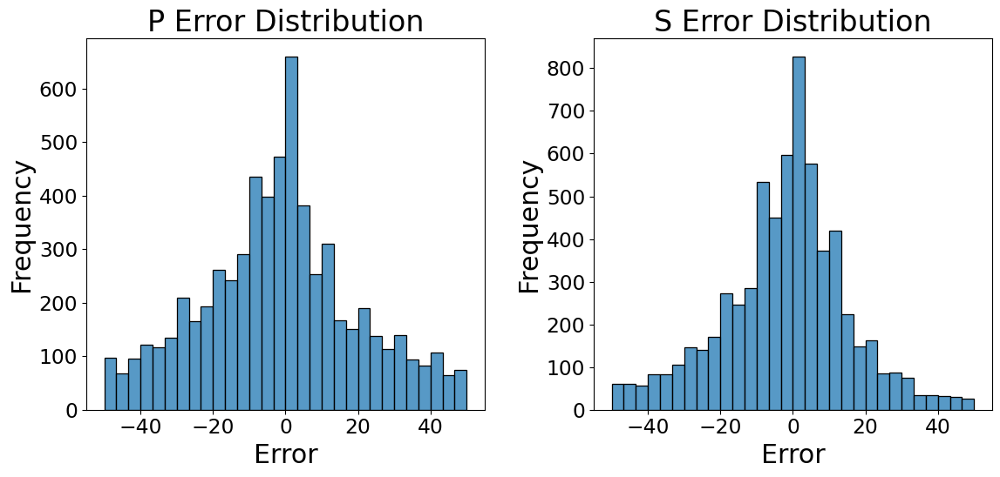

In [39]:

import matplotlib.pyplot as plt
import seaborn as sns

#绘制TP的误差图，x是误差，y是频率
#P,S分开绘图两张图，只需要绘制TP的部分
# 设置图形的大小
plt.figure(figsize=(12, 6))
# 绘制 P 的误差分布
plt.subplot(1, 2, 1)
sns.histplot(result_moe[result_moe['p_TP'] == 1]['p_error'], bins=30, kde=False)
plt.title('P Error Distribution')
plt.xlabel('Error')
plt.ylabel('Frequency')
# 绘制 S 的误差分布
plt.subplot(1, 2, 2)
sns.histplot(result_moe[result_moe['s_TP'] == 1]['s_error'], bins=30, kde=False)
plt.title('S Error Distribution')
plt.xlabel('Error')
plt.ylabel('Frequency')
# 显示图形
plt.tight_layout()
plt.show()

# PhaseNet

In [40]:


# 提取 eqt 中的 file_name
file_names = phasenet['trace_name']

# 筛选 stead 中 trace_name 与 file_name 匹配的行
filtered_stead = stead[stead['trace_name'].isin(file_names)]



# 合并两个数据框，基于 file_name 和 trace_name 的匹配
merged = pd.merge(phasenet, filtered_stead, left_on='trace_name', right_on='trace_name')


# 计算时间差（向量化操作）
merged['p_error'] = (merged['trace_p_arrival_sample'] - merged['p_idx'])
merged['s_error'] = (merged['trace_s_arrival_sample'] - merged['s_idx'])


# 选择需要的列
result_phasenet = merged[['trace_name','trace_category', 'trace_p_arrival_sample','trace_s_arrival_sample','p_idx','s_idx','p_error','s_error']]
# 将结果保存到 CSV 文件

result_phasenet

,trace_name,trace_category,trace_p_arrival_sample,trace_s_arrival_sample,p_idx,s_idx,p_error,s_error
0,"bucket454$1004,:3,:6000",earthquake_local,580.0,861.0,583,856.0,-3.0,5.0
1,"bucket359$715,:3,:6000",earthquake_local,618.0,731.0,622,734.0,-4.0,-3.0
2,"bucket142$569,:3,:6000",noise,NaN,NaN,28,NaN,NaN,NaN
3,"bucket369$93,:3,:6000",earthquake_local,489.0,641.0,491,645.0,-2.0,-4.0
4,"bucket437$624,:3,:6000",earthquake_local,269.0,560.0,278,559.0,-9.0,1.0
...,...,...,...,...,...,...,...,...
11592,"bucket436$439,:3,:6000",earthquake_local,698.0,1153.0,760,1161.0,-62.0,-8.0
11593,"bucket336$524,:3,:6000",earthquake_local,262.0,447.0,268,485.0,-6.0,-38.0
11594,"bucket414$327,:3,:6000",earthquake_local,972.0,1626.0,999,NaN,-27.0,NaN
11595,"bucket397$380,:3,:6000",earthquake_local,188.0,1686.0,197,1773.0,-9.0,-87.0


In [41]:
#计算TP，FP，FN设置TP阈值为50个点
TP_threshold_TP = 50
TP_threshold_FN= 50
result_phasenet.loc[:, 'p_TP'] = np.where(abs(result_phasenet['p_error']) <= TP_threshold_TP, 1, 0)
result_phasenet.loc[:, 's_TP'] = np.where(abs(result_phasenet['s_error']) <= TP_threshold_TP, 1, 0)

#FN表示大于0.5
result_phasenet.loc[:, 'p_FN'] = np.where(abs(result_phasenet['p_error']) > TP_threshold_FN, 1, 0)
result_phasenet.loc[:, 's_FN'] = np.where(abs(result_phasenet['s_error']) > TP_threshold_FN, 1, 0)

#FP表示trace_name里面含有噪声的数量，也就是trace_name列是noise的数量
result_phasenet.loc[:, 'p_FP'] = np.where(result_phasenet['trace_category'] == 'noise', 1, 0)
result_phasenet.loc[:, 's_FP'] = np.where(result_phasenet['trace_category'] == 'noise', 1, 0)

#计算stead的随机种子样本的noise个数
sampled_data = stead.sample(frac=ration, random_state=random_set)
sampled_data_count=len(stead.sample(frac=ration, random_state=random_set))
noise_count = len(sampled_data[sampled_data['trace_category'] == 'noise'])
earthquake_count=sampled_data_count - noise_count


#FP：噪声误报 + 未检测到的地震事件（除开噪声）
p_FP_count=result_phasenet.loc[:, 'p_FP'].sum()+ earthquake_count - result_phasenet.loc[:, 'p_TP'].sum() - result_phasenet.loc[:, 'p_FN'].sum()
s_FP_count=result_phasenet.loc[:, 's_FP'].sum()+ earthquake_count - result_phasenet.loc[:, 's_TP'].sum() - result_phasenet.loc[:, 's_FN'].sum()


#计算precision，recall，f1
p_TP= result_phasenet['p_TP'].sum()
s_TP= result_phasenet['s_TP'].sum()

p_FN= result_phasenet['p_FN'].sum()
s_FN= result_phasenet['s_FN'].sum()

# 计算precision，recall，f1
p_precision = p_TP / (p_TP + p_FP_count) if (p_TP + p_FP_count) > 0 else 0
s_precision = s_TP / (s_TP + s_FP_count) if (s_TP + s_FP_count) > 0 else 0

p_recall = p_TP / (p_TP + p_FN) if (p_TP + p_FN) > 0 else 0
s_recall = s_TP / (s_TP + s_FN) if (s_TP + s_FN) > 0 else 0

p_f1 = 2 * (p_precision * p_recall) / (p_precision + p_recall) if (p_precision + p_recall) > 0 else 0
s_f1 = 2 * (s_precision * s_recall) / (s_precision + s_recall) if (s_precision + s_recall) > 0 else 0

#计算MAE，标准差
result_phasenet.loc[:, 'p_TP_mae'] = np.where(result_phasenet['p_TP'] == 1, result_phasenet['p_error'], 0)
result_phasenet.loc[:, 's_TP_mae'] = np.where(result_phasenet['s_TP'] == 1, result_phasenet['s_error'], 0)
# 计算 TP 的平均绝对误差
p_TP_mae = abs(result_phasenet['p_TP_mae']).sum() / p_TP if p_TP > 0 else 0
s_TP_mae = abs(result_phasenet['s_TP_mae']).sum() / s_TP if s_TP > 0 else 0
#mae还需要除100，
p_TP_mae = p_TP_mae / 100
s_TP_mae = s_TP_mae / 100

#计算TP的标准差误差
p_TP_std = result_phasenet['p_TP_mae'].std() / 100
s_TP_std = result_phasenet['s_TP_mae'].std() / 100



print("P-TP:", p_TP)
print("P-FP:", p_FP_count)
print("P-FN:", p_FN)
print("P-Precision:", p_precision)
print("P-Recall:", p_recall)
print("P-F1 Score:", p_f1)
print("P-MAE:", p_TP_mae)
print("P-STD:", p_TP_std)

print("S-TP:", s_TP)
print("S-FP:", s_FP_count)
print("S-FN:", s_FN)
print("S-Precision:", s_precision)
print("S-Recall:", s_recall)
print("S-F1 Score:", s_f1)
print("S-MAE:", s_TP_mae)
print("S-STD:", s_TP_std)

#将结果做成一个表格
result_table_phasenet = pd.DataFrame({
    'PhaseNet': ['TP', 'FP', 'FN', 'Precision', 'Recall', 'F1 Score', 'MAE', 'STD'],
    'P': [p_TP, p_FP_count, p_FN, p_precision, p_recall, p_f1, p_TP_mae, p_TP_std],
    'S': [s_TP, s_FP_count, s_FN, s_precision, s_recall, s_f1, s_TP_mae, s_TP_std]
})

# 指定需要转换为整数的行
int_rows = ['TP', 'FP', 'FN']

# 对 'P' 和 'S' 列中符合条件的行转换为整数
result_table_phasenet.loc[result_table_phasenet['PhaseNet'].isin(int_rows), ['P', 'S']] = (
    result_table_phasenet.loc[result_table_phasenet['PhaseNet'].isin(int_rows), ['P', 'S']]
    .astype(int)  # 强制转换为整数
)


P-TP: 6775
P-FP: 3139
P-FN: 2101
P-Precision: 0.6833770425660682
P-Recall: 0.7632942767012167
P-F1 Score: 0.7211282597126131
P-MAE: 0.09357047970479705
P-STD: 0.09994638936483458
S-TP: 5873
S-FP: 3548
S-FN: 2594
S-Precision: 0.6233945441035983
S-Recall: 0.6936341088933506
S-F1 Score: 0.6566413237924865
S-MAE: 0.12491060786650773
S-STD: 0.11356460482962408


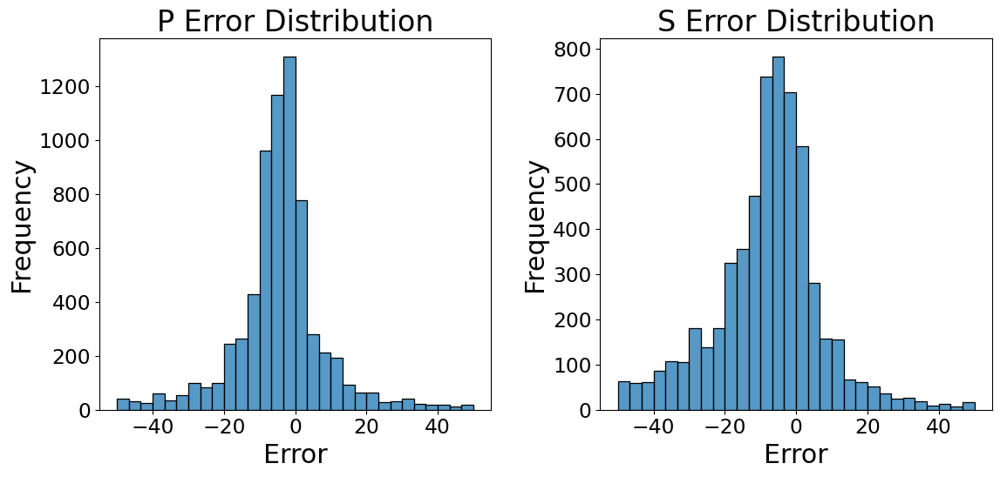

In [42]:

import matplotlib.pyplot as plt
import seaborn as sns

#绘制TP的误差图，x是误差，y是频率
#P,S分开绘图两张图，只需要绘制TP的部分
# 设置图形的大小
plt.figure(figsize=(12, 6))
# 绘制 P 的误差分布
plt.subplot(1, 2, 1)
data=result_phasenet[result_phasenet['p_TP'] == 1]['p_error']

sns.histplot(result_phasenet[result_phasenet['p_TP'] == 1]['p_error'], bins=30, kde=False)
plt.title('P Error Distribution')
plt.xlabel('Error')
plt.ylabel('Frequency')
# 绘制 S 的误差分布
plt.subplot(1, 2, 2)
sns.histplot(result_phasenet[result_phasenet['s_TP'] == 1]['s_error'], bins=30, kde=False)
plt.title('S Error Distribution')
plt.xlabel('Error')
plt.ylabel('Frequency')
# 显示图形
plt.tight_layout()
plt.show()

# Results

In [43]:
import pandas as pd

# 1) 以 EQT 表举例
df_eqt = result_table_eqt.set_index('EQT')
# 将原本的列 ['P', 'S'] 改成多层索引：最上层 'EQT'，第二层保持原列名
df_eqt.columns = pd.MultiIndex.from_tuples([('EQT', col) for col in df_eqt.columns])

# 2) Moe 表同理
df_moe = result_table_moe.set_index('Moe')
df_moe.columns = pd.MultiIndex.from_tuples([('Moe', col) for col in df_moe.columns])

# 3) PhaseNet 表
df_phasenet = result_table_phasenet.set_index('PhaseNet')
df_phasenet.columns = pd.MultiIndex.from_tuples([('PhaseNet', col) for col in df_phasenet.columns])

# 4) 横向合并
df_multi = pd.concat([df_moe,df_eqt, df_phasenet], axis=1)

print('----------------------------------------------Texd------------------------------------------')
df_multi


----------------------------------------------Texd------------------------------------------


Moe                       EQT                  PhaseNet  \
                     P            S            P            S            P   
TP         6225.000000  6428.000000  6558.000000  6859.000000  6775.000000   
FP         1450.000000  1494.000000  1272.000000  1344.000000  3139.000000   
FN         1888.000000  1641.000000  1495.000000  1122.000000  2101.000000   
Precision     0.811075     0.811411     0.837548     0.836158     0.683377   
Recall        0.767287     0.796629     0.814355     0.859416     0.763294   
F1 Score      0.788574     0.803952     0.825789     0.847627     0.721128   
MAE           0.166586     0.130117     0.174799     0.105963     0.093570   
STD           0.184520     0.151959     0.200614     0.135344     0.099946   

                        
                     S  
TP         5873.000000  
FP         3548.000000  
FN         2594.000000  
Precision     0.623395  
Recall        0.693634  
F1 Score      0.656641  
MAE           0.124911  
STD           0.113565

| Texd    | MoeP     | MoeS     | EQTP     | EQTS     | PHNP     | PHPS     |
|-----------|----------|----------|----------|----------|----------|----------|
| TP        | 6558     | 6859     | 6225     | 6428     | 6775     | 5873     |
| FP        | 1272     | 1344     | 1450     | 1494     | 3139     | 3548     |
| FN        | 1495     | 1122     | 1888     | 1641     | 2101     | 2594     |
| Precision | 0.837548 | 0.836158 | 0.811075 | 0.811411 | 0.683377 | 0.623395 |
| Recall    | 0.814355 | 0.859416 | 0.767287 | 0.796629 | 0.763294 | 0.693634 |
| F1-Score  | 0.825789 | 0.847627 | 0.788574 | 0.803952 | 0.721128 | 0.656641 |
| MAE (s)   | 0.093570 | 0.105963 | 0.176000 | 0.130000 | 0.174799 | 0.124911 |
| STD (s)   | 0.099946 | 0.135344 | 0.180000 | 0.150000 | 0.200614 | 0.113565 |

# EQT Figure

In [44]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.cm as cm
import matplotlib.colors as colors
import scienceplots
import os
from matplotlib.ticker import FuncFormatter

base_fontsize = 50

plt.rcParams.update({
    'font.size': base_fontsize,
    'axes.titlesize': base_fontsize * 1.0,
    'axes.labelsize': base_fontsize * 0.9,
    'xtick.labelsize': base_fontsize * 0.7,
    'ytick.labelsize': base_fontsize * 0.7,
    'legend.fontsize': base_fontsize * 0.8,
    'figure.titlesize': base_fontsize * 1.2
})

cmap_pos = plt.get_cmap('viridis').reversed()
cmap_neg = plt.get_cmap('viridis')

def plot_error_distribution(data, title, xlabel, mae, sigma, store_path, filename):
    with plt.style.context(['science', 'ieee']):
        fig, ax = plt.subplots(figsize=(10, 6))
        counts, bins = np.histogram(data, bins=30)
        max_pos, min_neg = 0.5, -0.5
        norm_pos = colors.Normalize(vmin=0, vmax=max_pos)
        norm_neg = colors.Normalize(vmin=min_neg, vmax=0)

        for count, left, right in zip(counts, bins[:-1], bins[1:]):
            center = 0.5 * (left + right)
            color = cmap_pos(norm_pos(center)) if center >= 0 else cmap_neg(norm_neg(center))
            ax.bar(center, count, width=right - left, color=color, align='center')

        ax.set_title(title, pad=20)
        # ax.set_xlabel(xlabel, labelpad=15)
        ax.set_ylim(0, counts.max() * 1.1)
        ax.set_xticks([])

        # 设置 y 轴的显示格式
        ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f'{y / 1e3:.1f}' if y < 1000 else f'{y / 1e3:.0f}'))

        # 在 y 轴顶部添加 ×10³
        ax.text(0, 1.01, r'$\times 10^3$',
                transform=ax.transAxes,
                fontsize=base_fontsize * 0.7,
                ha='left', va='bottom')

        # 添加统计信息文本框
        stats_text = f'$\\mathrm{{MAE}}={mae}\\,\\mathrm{{s}}$\n$\\sigma={sigma}\\,\\mathrm{{s}}$'
        ax.text(0.95, 0.95, stats_text,
                transform=ax.transAxes,
                ha='right', va='top',
                fontsize=base_fontsize * 0.6,
                bbox=dict(facecolor='white', alpha=0.8, edgecolor='none', pad=10))

        plt.tight_layout()
        path = os.path.join(store_path, filename)
        plt.savefig(path, dpi=600, bbox_inches='tight')
        plt.show()


/tmp/ipykernel_2029556/3497951265.py:21: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_pos = cm.get_cmap('viridis').reversed()
/tmp/ipykernel_2029556/3497951265.py:22: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_neg = cm.get_cmap('viridis')


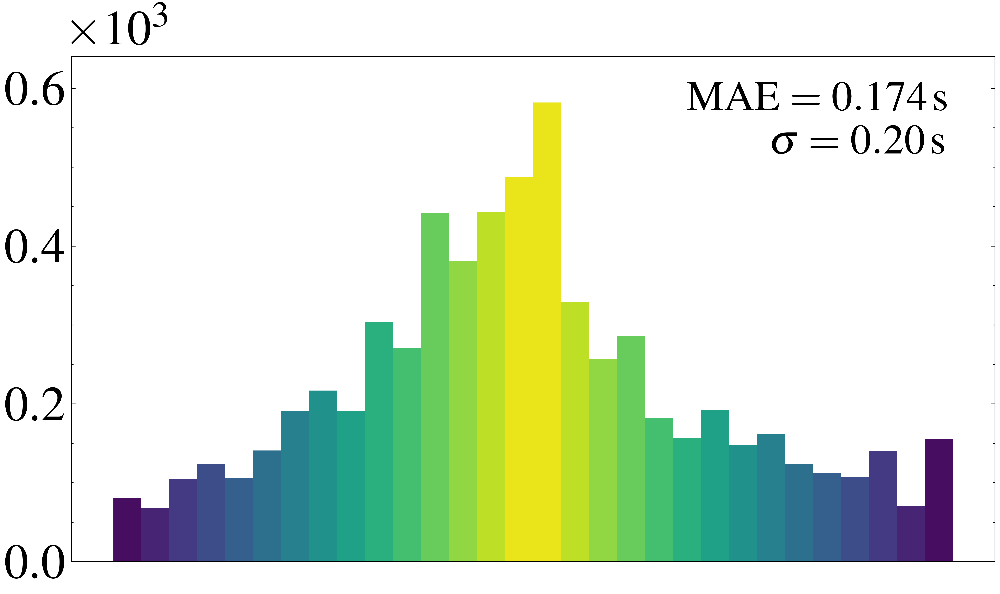

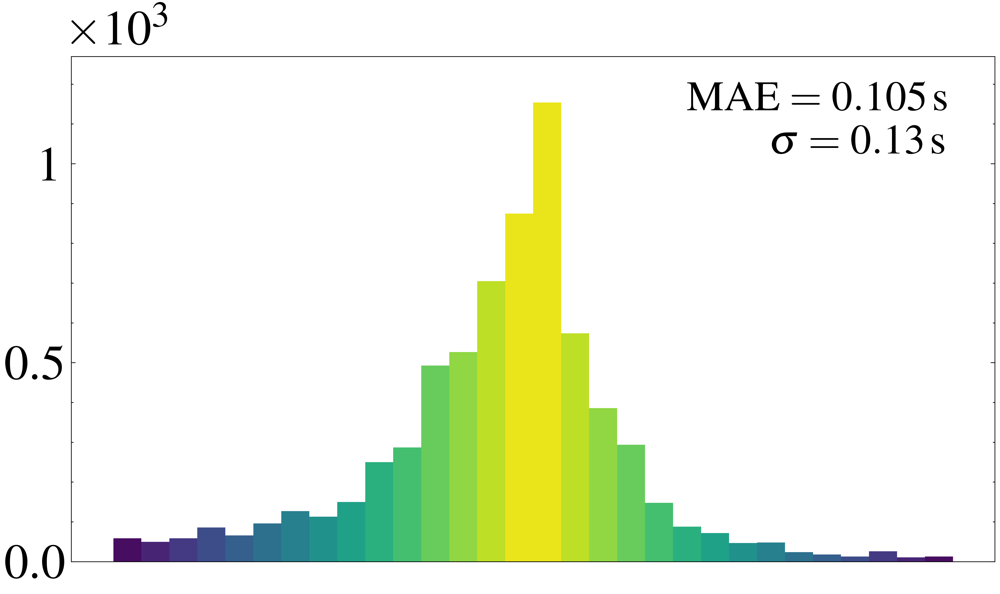

In [45]:

# 绘制P波
data_p = result_eqt[result_eqt['p_TP'] == 1]['p_error']/100
plot_error_distribution(data_p,
                      '',
                      'PhaseNet P Picking Error (s)',
                      '0.174', '0.20',
                      '/home/yuan/code/SeisMoE/results/RESULT_FIGURE/Texd',
                      'PhaseNet_P_error_distribution.svg')

# 绘制S波
data_s = result_eqt[result_eqt['s_TP'] == 1]['s_error']/100
plot_error_distribution(data_s,
                      '',
                      'SeisMoe S Picking Error (s)',
                      '0.105', '0.13',
                        '/home/yuan/code/SeisMoE/results/RESULT_FIGURE/Texd',
                      'SeisMoe_S_error_distribution.svg')

# Moe Figure

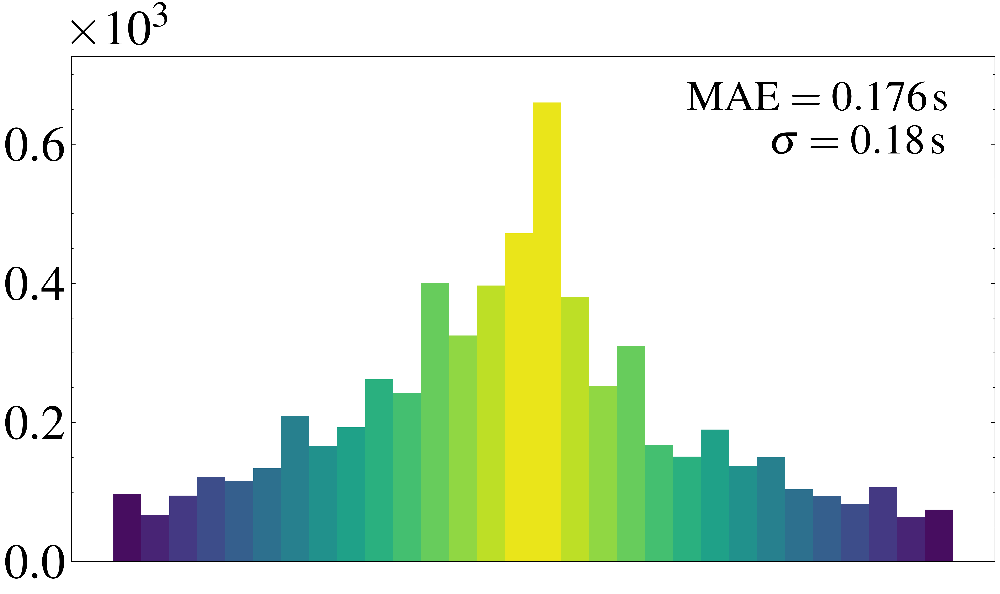

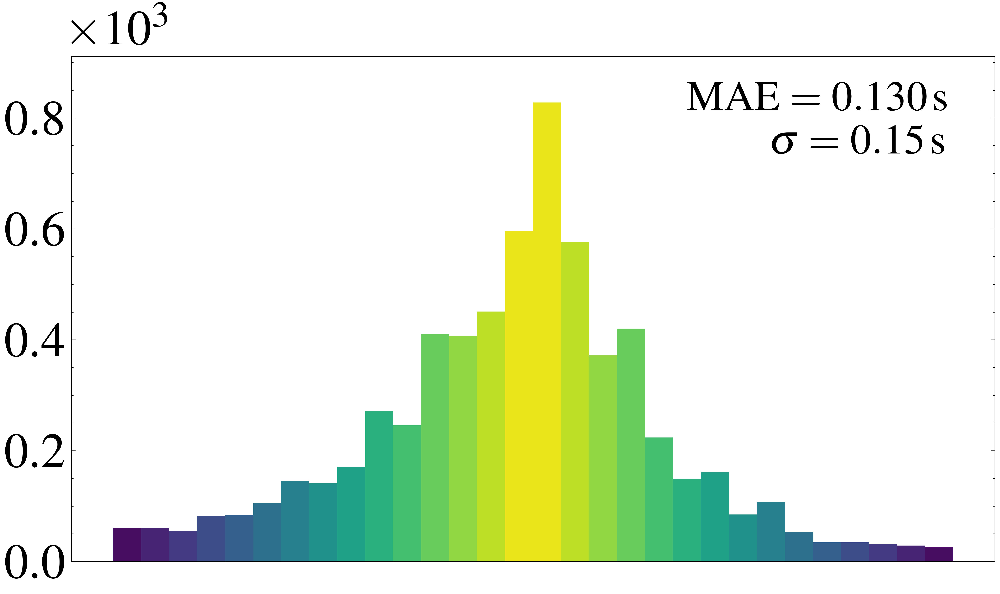

In [46]:

# 绘制P波
data_p = result_moe[result_moe['p_TP'] == 1]['p_error']/100
plot_error_distribution(data_p,
                      '',
                      'EQTransformer P Picking Error (s)',
                      '0.176', '0.18',
                        '/home/yuan/code/SeisMoE/results/RESULT_FIGURE/Texd',
                      'EQTransformer_P_error_distribution.svg')

# 绘制S波
data_s = result_moe[result_moe['s_TP'] == 1]['s_error']/100
plot_error_distribution(data_s,
                      '',
                      'EQTransformer S Picking Error (s)',
                      '0.130', '0.15',
                        '/home/yuan/code/SeisMoE/results/RESULT_FIGURE/Texd',
                      'EQTransformer_S_error_distribution.svg')

# PhaseNet Figure

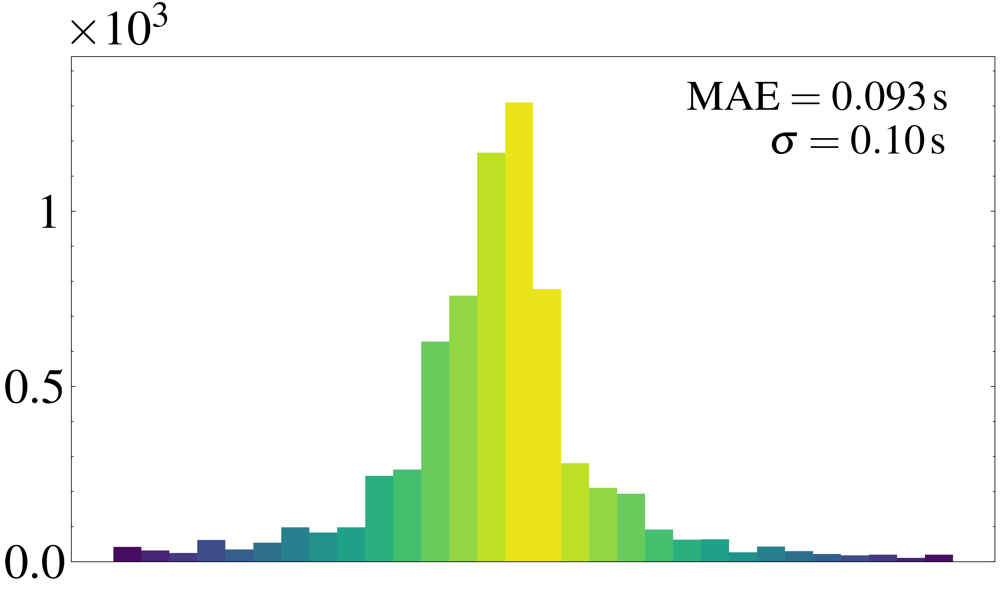

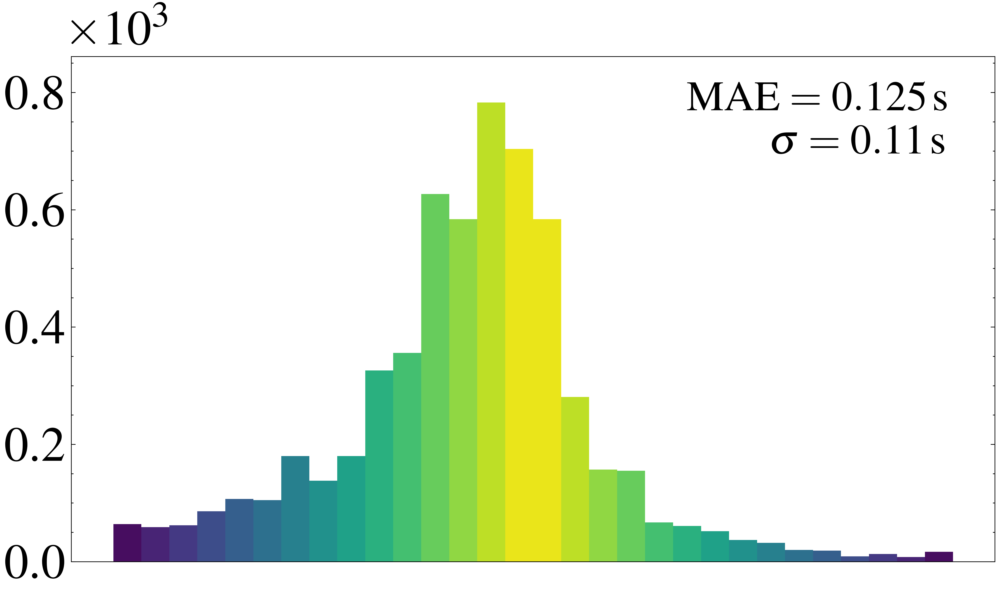

In [47]:

# 绘制P波
data_p = result_phasenet[result_phasenet['p_TP'] == 1]['p_error']/100
plot_error_distribution(data_p,
                      '',
                      'SeisMoe P Picking Error (s)',
                      '0.093', '0.10',
                        '/home/yuan/code/SeisMoE/results/RESULT_FIGURE/Texd',
                      'SeisMoe_P_error_distribution.svg')

# 绘制S波
data_s = result_phasenet[result_phasenet['s_TP'] == 1]['s_error']/100
plot_error_distribution(data_s,
                      '',
                      'PhaseNet S Picking Error (s)',
                      '0.125', '0.11',
                        '/home/yuan/code/SeisMoE/results/RESULT_FIGURE/Texd',
                      'PhaseNet_S_error_distribution.svg')

# Texd Samples Figure

## Moe predict

In [48]:
    # trace_name='bucket344$619,:3,:6000' #bucket344$619,:3,:60000_M1.4



    #!/usr/bin/env python
    # -*- coding: utf-8 -*-
def Moe_predict(trace_name):
        import os
        import random
        import sys
        import h5py
        import numpy as np
        import pandas as pd
        import torch
        from scipy.signal import find_peaks
        from torch.utils.data import Dataset, DataLoader
        from tqdm import tqdm
        from datetime import datetime, timedelta
        import multiprocessing as mp
        from scipy.signal import resample,butter,filtfilt
        import os
        os.environ["CUDA_VISIBLE_DEVICES"]="1"
        # 将自定义模型文件所在目录加入路径
        sys.path.append("/home/yuan/code/SeisMoE/src")
        # 导入自定义模型文件，假设其中包含与 seisbench EQTransformer 接口相同的模型类
        from model_moe_gpt_PS2_CPU import IMG1

        def detect_phases(p_arr, s_arr, p_thresh=0.3, s_thresh=0.3):
            """使用 scipy.signal.find_peaks 实现相位检测"""
            p_peaks, p_props = find_peaks(p_arr, height=p_thresh, distance=100)
            s_peaks, s_props = find_peaks(s_arr, height=s_thresh, distance=100)

            best_p = p_peaks[p_props['peak_heights'].argmax()] if len(p_peaks) > 0 else None
            best_s = None

            if best_p is not None:
                for s in s_peaks:
                    if 0 < (s - best_p) < 6000:  # 60秒窗口(100Hz采样)
                        best_s = s
                        break

            return best_p, best_s, p_props['peak_heights'].max() if best_p is not None else None, \
                s_props['peak_heights'][s_peaks.tolist().index(best_s)] if best_s is not None else None



        def normalize_data1(data, mode='std'):
            data -= np.mean(data, axis=1, keepdims=True)

            if mode == 'std':
                std_val = np.std(data, axis=1, keepdims=True)
                std_val[std_val == 0] = 1.0
                data /= std_val
            elif mode == 'max':
                max_val = np.max(np.abs(data), axis=1, keepdims=True)
                max_val[max_val == 0] = 1.0
                data /= max_val
            else:
                raise ValueError(f"Unsupported norm_mode: {mode}")
            return data


        def bandpass_filter(data, lowcut, highcut, fs, order=4):
            """
            对每个通道数据进行带通滤波。
            data: 形状为 (3, T)
            lowcut, highcut: 滤波器截止频率
            fs: 采样率
            """
            nyquist = 0.5 * fs
            low = lowcut / nyquist
            high = highcut / nyquist
            b, a = butter(order, [low, high], btype='band')

            filtered = np.zeros_like(data)
            for ch in range(data.shape[0]):
                filtered[ch] = filtfilt(b, a, data[ch])
            return filtered



        def model_predict(model, data: torch.Tensor):
            with torch.no_grad():
                return model(data)




        hdf5_path="/home/cloudlab/Code_DL/DEEP_STEAD_PYTORCH/Pytorch_STEAD/DATA/Texd.hdf5"
        p_thresh=0.1,
        s_thresh=0.1
        trace_names = trace_name



        with h5py.File(hdf5_path, 'r') as f:
            if 'data' not in f:
                raise KeyError("HDF5文件中缺少'data'组")

            group = trace_name.split('$')[0].strip()
            index = int(trace_name.split('$')[1].split(',')[0].strip())

            dataset = f['data'].get(group)
            normalized = dataset[index, :, :].astype(np.float32)
            # normalized = dataset[:].T  # shape: (3, n_samples)
        # normalized = (normalized - np.mean(normalized, axis=0)) / (np.std(normalized, axis=0) + 1e-10)
        # 滤波：1-45Hz 带通滤波
        # normalized = bandpass_filter(normalized, lowcut=1.0, highcut=45.0, fs=100)
        #
        # # 标准化
        normalized = normalize_data1(normalized, 'std')
        data=torch.from_numpy(normalized.T).unsqueeze(0)


        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

        # 加载自定义模型
        # 此处假设模型文件 model_moe_gpt_PS3_CPU.py 中定义的类名为 EQTransformer
        model = IMG1().to(device)
        model.load_state_dict(torch.load("/home/yuan/code/SeisMoE/models/Model_Store/CPU2_moe/best_model.pth",map_location=device))

        model.eval()

        results = []
        data = data.to(device)
        # 进行模型推理，假设返回格式与 seisbench 的 EQTransformer 一致，
        # 其中 output[1] 为 P 概率，output[2] 为 S 概率
        output,_ = model_predict(model, data)
        moe_p_prob= output[0].cpu()
        moe_s_prob= output[1].cpu()

        for i, (p_arr, s_arr) in enumerate(zip(moe_p_prob, moe_s_prob)):
            p_idx, s_idx, p_conf, s_conf = detect_phases(p_arr.numpy(), s_arr.numpy(), p_thresh, s_thresh)
            if p_idx is not None or s_idx is not None:
                results.append((i, p_idx, s_idx, p_conf, s_conf))

        # output_csv = os.path.join(output_dir, 'picks——moe2.csv')
        results=pd.DataFrame(results, columns=['trace_name', 'p_idx', 's_idx', 'p_conf', 's_conf'])

        moe_p=results['p_idx'].values[0]
        moe_s=results['s_idx'].values[0]
        moe_pc=results['p_conf'].values[0]
        moe_sc=results['s_conf'].values[0]


        print(f"Moe P index:{results['p_idx'].values[0]}")
        print(f"Moe S index:{results['s_idx'].values[0]}")
        print(f"Moe P confidence:{results['p_conf'].values[0]}")
        print(f"Moe S confidence:{results['s_conf'].values[0]}")

        return moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob






## EQT Predict

In [49]:
    #!/usr/bin/env python
    # -*- coding: utf-8 -*-
def EQT_Predict(trace_name):
        import os
        import random
        import h5py
        import numpy as np
        import pandas as pd
        import torch
        from scipy.signal import find_peaks
        from torch.utils.data import Dataset, DataLoader
        import seisbench.models as sbm
        from tqdm import tqdm
        from datetime import datetime, timedelta
        import multiprocessing as mp
        import h5py
        import numpy as np
        import torch
        from torch.utils.data import Dataset
        from scipy.signal import resample,butter,filtfilt
        import os
        os.environ["CUDA_VISIBLE_DEVICES"]="2"
        def detect_phases(p_arr, s_arr, p_thresh=0.3, s_thresh=0.3):
            """使用 scipy.signal.find_peaks 实现相位检测，
            逻辑：仅根据 p_arr 中幅值最高的峰确定 P，
            然后在 P 后面 6000 个采样点内，从 s_arr 中选择幅值最高的峰作为 S。
            """
            # 对 p_arr 和 s_arr 分别进行峰值检测
            p_peaks, p_props = find_peaks(p_arr, height=p_thresh, distance=100)
            s_peaks, s_props = find_peaks(s_arr, height=s_thresh, distance=100)

            # 选择 p_arr 中最高的峰作为 P
            if len(p_peaks) > 0:
                best_p_index = np.argmax(p_props['peak_heights'])
                best_p = p_peaks[best_p_index]
                p_conf = p_props['peak_heights'][best_p_index]
            else:
                best_p = None
                p_conf = None

            best_s = None
            s_conf = None

            if best_p is not None:
                # 筛选出在 P 后且距离 P 小于 6000 个采样点的所有 S 峰
                valid_s_indices = [i for i, s in enumerate(s_peaks) if s > best_p and (s - best_p) < 6000]
                if valid_s_indices:
                    valid_s_peaks = s_peaks[valid_s_indices]
                    valid_s_props = s_props['peak_heights'][valid_s_indices]
                    best_s_idx = np.argmax(valid_s_props)
                    best_s = valid_s_peaks[best_s_idx]
                    s_conf = valid_s_props[best_s_idx]
            return best_p, best_s, p_conf, s_conf


        def normalize_data(data, mode='std'):
            data -= np.mean(data, axis=1, keepdims=True)

            if mode == 'std':
                std_val = np.std(data, axis=1, keepdims=True)
                std_val[std_val == 0] = 1.0
                data /= std_val
            elif mode == 'max':
                max_val = np.max(np.abs(data), axis=1, keepdims=True)
                max_val[max_val == 0] = 1.0
                data /= max_val
            else:
                raise ValueError(f"Unsupported norm_mode: {mode}")
            return data


        def bandpass_filter(data, lowcut, highcut, fs, order=4):
            """
            对每个通道数据进行带通滤波。
            data: 形状为 (3, T)
            lowcut, highcut: 滤波器截止频率
            fs: 采样率
            """
            nyquist = 0.5 * fs
            low = lowcut / nyquist
            high = highcut / nyquist
            b, a = butter(order, [low, high], btype='band')

            filtered = np.zeros_like(data)
            for ch in range(data.shape[0]):
                filtered[ch] = filtfilt(b, a, data[ch])
            return filtered



        def model_predict(model, data: torch.Tensor):
            with torch.no_grad():
                return model(data)

        # def main(trace_name, hdf5_path, p_thresh=0.3, s_thresh=0.3, batch_size=2048):



        hdf5_path=r'/home/cloudlab/Code_DL/DEEP_STEAD_PYTORCH/Pytorch_STEAD/DATA/Texd.hdf5'
        p_thresh=0.1
        s_thresh=0.1
        trace_names = trace_name



        with h5py.File(hdf5_path, 'r') as f:
            if 'data' not in f:
                raise KeyError("HDF5文件中缺少'data'组")

            group = trace_name.split('$')[0].strip()
            index = int(trace_name.split('$')[1].split(',')[0].strip())

            dataset = f['data'].get(group)
            normalized = dataset[index, :, :].astype(np.float32)
        # normalized = (normalized - np.mean(normalized, axis=0)) / (np.std(normalized, axis=0) + 1e-10)
        # 滤波：1-45Hz 带通滤波
        normalized = bandpass_filter(normalized, lowcut=1.0, highcut=40.0, fs=100)
        #
        # # 标准化
        normalized = normalize_data(normalized, 'std')
        data=torch.from_numpy(normalized).unsqueeze(0)

        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

        # 加载自定义模型
        # 此处假设模型文件 model_moe_gpt_PS3_CPU.py 中定义的类名为 EQTransformer
        model = sbm.EQTransformer.from_pretrained("original").to(device).eval()

        results = []
        data = data.to(device)
        # 进行模型推理，假设返回格式与 seisbench 的 EQTransformer 一致，
        # 其中 output[1] 为 P 概率，output[2] 为 S 概率
        output= model_predict(model, data)
        eqt_p_prob= output[1].cpu()
        eqt_s_prob= output[2].cpu()

        for i, (p_arr, s_arr) in enumerate(zip(eqt_p_prob, eqt_s_prob)):
            p_idx, s_idx, p_conf, s_conf = detect_phases(p_arr.numpy(), s_arr.numpy(), p_thresh, s_thresh)
            if p_idx is not None or s_idx is not None:
                results.append((i, p_idx, s_idx, p_conf, s_conf))


        results=pd.DataFrame(results, columns=['trace_name', 'p_idx', 's_idx', 'p_conf', 's_conf'])
        eqt_p=results['p_idx'].values[0]
        eqt_s=results['s_idx'].values[0]
        eqt_pc=results['p_conf'].values[0]
        eqt_sc=results['s_conf'].values[0]
        # print(f"****拾取到的事件数：{len(results)}")
        print(f"eqt P index:{results['p_idx'].values[0]}")
        print(f"eqt S index:{results['s_idx'].values[0]}")
        print(f"eqt P confidence:{results['p_conf'].values[0]}")
        print(f"eqt S confidence:{results['s_conf'].values[0]}")

        return eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob


## PhaseNet Predict

In [50]:
    #!/usr/bin/env python
    # -*- coding: utf-8 -*-
def PhaseNet_predict(trace_name):
        import os
        import random
        import h5py
        import numpy as np
        import pandas as pd
        import torch
        from scipy.signal import find_peaks
        from torch.utils.data import Dataset, DataLoader
        import seisbench.models as sbm
        from tqdm import tqdm
        from datetime import datetime, timedelta
        import multiprocessing as mp
        import h5py
        import numpy as np
        import torch
        from torch.utils.data import Dataset
        from scipy.signal import resample,butter,filtfilt
        import os
        os.environ["CUDA_VISIBLE_DEVICES"]="2"
        def detect_phases(p_arr, s_arr, p_thresh=0.3, s_thresh=0.3):
            """使用 scipy.signal.find_peaks 实现相位检测，
            逻辑：仅根据 p_arr 中幅值最高的峰确定 P，
            然后在 P 后面 6000 个采样点内，从 s_arr 中选择幅值最高的峰作为 S。
            """
            # 对 p_arr 和 s_arr 分别进行峰值检测
            p_peaks, p_props = find_peaks(p_arr, height=p_thresh, distance=100)
            s_peaks, s_props = find_peaks(s_arr, height=s_thresh, distance=100)

            # 选择 p_arr 中最高的峰作为 P
            if len(p_peaks) > 0:
                best_p_index = np.argmax(p_props['peak_heights'])
                best_p = p_peaks[best_p_index]
                p_conf = p_props['peak_heights'][best_p_index]
            else:
                best_p = None
                p_conf = None

            best_s = None
            s_conf = None

            if best_p is not None:
                # 筛选出在 P 后且距离 P 小于 6000 个采样点的所有 S 峰
                valid_s_indices = [i for i, s in enumerate(s_peaks) if s > best_p and (s - best_p) < 6000]
                if valid_s_indices:
                    valid_s_peaks = s_peaks[valid_s_indices]
                    valid_s_props = s_props['peak_heights'][valid_s_indices]
                    best_s_idx = np.argmax(valid_s_props)
                    best_s = valid_s_peaks[best_s_idx]
                    s_conf = valid_s_props[best_s_idx]
            return best_p, best_s, p_conf, s_conf


        def normalize_data(data, mode='std'):
            data -= np.mean(data, axis=1, keepdims=True)

            if mode == 'std':
                std_val = np.std(data, axis=1, keepdims=True)
                std_val[std_val == 0] = 1.0
                data /= std_val
            elif mode == 'max':
                max_val = np.max(np.abs(data), axis=1, keepdims=True)
                max_val[max_val == 0] = 1.0
                data /= max_val
            else:
                raise ValueError(f"Unsupported norm_mode: {mode}")
            return data


        def bandpass_filter(data, lowcut, highcut, fs, order=4):
            """
            对每个通道数据进行带通滤波。
            data: 形状为 (3, T)
            lowcut, highcut: 滤波器截止频率
            fs: 采样率
            """
            nyquist = 0.5 * fs
            low = lowcut / nyquist
            high = highcut / nyquist
            b, a = butter(order, [low, high], btype='band')

            filtered = np.zeros_like(data)
            for ch in range(data.shape[0]):
                filtered[ch] = filtfilt(b, a, data[ch])
            return filtered



        def model_predict(model, data: torch.Tensor):
            with torch.no_grad():
                return model(data)

        # def main(trace_name, hdf5_path, p_thresh=0.3, s_thresh=0.3, batch_size=2048):



        hdf5_path=r'/home/cloudlab/Code_DL/DEEP_STEAD_PYTORCH/Pytorch_STEAD/DATA/Texd.hdf5'
        p_thresh=0.1
        s_thresh=0.1
        trace_names = trace_name



        with h5py.File(hdf5_path, 'r') as f:
            if 'data' not in f:
                raise KeyError("HDF5文件中缺少'data'组")

            group = trace_name.split('$')[0].strip()
            index = int(trace_name.split('$')[1].split(',')[0].strip())

            dataset = f['data'].get(group)
            normalized = dataset[index, :, :].astype(np.float32)
        # normalized = (normalized - np.mean(normalized, axis=0)) / (np.std(normalized, axis=0) + 1e-10)
        # 滤波：1-45Hz 带通滤波
        normalized = bandpass_filter(normalized, lowcut=1.0, highcut=40.0, fs=100)
        #
        # # 标准化
        normalized = normalize_data(normalized, 'std')
        data=torch.from_numpy(normalized).unsqueeze(0)

        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

        # 加载自定义模型
        # 此处假设模型文件 model_moe_gpt_PS3_CPU.py 中定义的类名为 EQTransformer
        model = sbm.PhaseNet.from_pretrained("original").to(device).eval()

        results = []
        data = data.to(device)
        # 进行模型推理，假设返回格式与 seisbench 的 EQTransformer 一致，
        # 其中 output[1] 为 P 概率，output[2] 为 S 概率
        output= model_predict(model, data)
        phasenet_p_prob= output[:,1,:].cpu()
        phasenet_s_prob= output[:,2,:].cpu()

        for i, (p_arr, s_arr) in enumerate(zip(phasenet_p_prob, phasenet_s_prob)):
            p_idx, s_idx, p_conf, s_conf = detect_phases(p_arr.numpy(), s_arr.numpy(), p_thresh, s_thresh)
            if p_idx is not None or s_idx is not None:
                results.append((i, p_idx, s_idx, p_conf, s_conf))


        results=pd.DataFrame(results, columns=['trace_name', 'p_idx', 's_idx', 'p_conf', 's_conf'])
        phasenet_p=results['p_idx'].values[0]
        phasenet_s=results['s_idx'].values[0]
        phasenet_pc=results['p_conf'].values[0]
        phasenet_sc=results['s_conf'].values[0]
        # print(f"****拾取到的事件数：{len(results)}")
        print(f"phasenet P index:{results['p_idx'].values[0]}")
        print(f"phasenet S index:{results['s_idx'].values[0]}")
        print(f"phasenet P confidence:{results['p_conf'].values[0]}")
        print(f"phasenet S confidence:{results['s_conf'].values[0]}")

        return phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob


## sigale figure

In [51]:
from scipy.signal import resample,butter,filtfilt
plt.rcParams['lines.linewidth'] = 0.3  # 设置默认线宽为1.0
def Example_Figure(trace_name,
                   moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob,
                   eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob,
                   phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob,
                   Pquen1=50,
                   Pquen2=50,
                   Squen1=100,
                   Squen2=100,
                   store_path='/home/yuan/code/SeisMoE/results/RESULT_FIGURE/Instance',
                   store_name='trace_name'):
    cs=r'/home/cloudlab/Code_DL/DEEP_STEAD_PYTORCH/Pytorch_STEAD/DATA/Texd.csv'
    csv_data=pd.read_csv(cs)
    Psample=csv_data[csv_data['trace_name']==trace_name]['trace_p_arrival_sample'].values[0]
    Ssample=csv_data[csv_data['trace_name']==trace_name]['trace_s_arrival_sample'].values[0]
    print(f"Psample:{Psample}")
    print(f"Ssample:{Ssample}")
    import scienceplots
    import matplotlib.pyplot as plt
    from mpl_toolkits.axes_grid1.inset_locator import inset_axes
    from matplotlib.patches import ConnectionPatch
    import h5py

    Pquen1=Pquen1
    Pquen2=Pquen2
    Squen1=Squen1
    Squen2=Squen2
    base_fontsize = 24  # 只需修改这个值即可全局调整

    plt.rcParams.update({
        'font.size': base_fontsize,
        'axes.titlesize': base_fontsize * 1.0,    # 标题=基准大小
        'axes.labelsize': base_fontsize * 0.9,    # 坐标轴标签=90%
        'xtick.labelsize': base_fontsize * 0.7,   # 刻度标签=70%
        'ytick.labelsize': base_fontsize * 0.7,
        'legend.fontsize': base_fontsize * 0.6,   # 图例=80%
        'figure.titlesize': base_fontsize * 1.2   # 图形标题=120%
    })


    try:
        phasenet_p_prob=np.squeeze(phasenet_p_prob.numpy())
        phasenet_s_prob=np.squeeze(phasenet_s_prob.numpy())
        eqt_p_prob=np.squeeze(eqt_p_prob.numpy())
        eqt_s_prob=np.squeeze(eqt_s_prob.numpy())
        moe_p_prob=np.squeeze(moe_p_prob.numpy())
        moe_s_prob=np.squeeze(moe_s_prob.numpy())
    except:
        pass


    def normalize_data1(data, mode='std'):
        data -= np.mean(data, axis=1, keepdims=True)

        if mode == 'std':
            std_val = np.std(data, axis=1, keepdims=True)
            std_val[std_val == 0] = 1.0
            data /= std_val
        elif mode == 'max':
            max_val = np.max(np.abs(data), axis=1, keepdims=True)
            max_val[max_val == 0] = 1.0
            data /= max_val
        else:
            raise ValueError(f"Unsupported norm_mode: {mode}")
        return data

    def normalize_data2(data, mode='max'):
        data -= np.mean(data, axis=0, keepdims=True)
        if mode == 'max':
            max_data = np.max(data, axis=0, keepdims=True)
            assert (max_data.shape[-1] == data.shape[-1])
            max_data[max_data == 0] = 1
            data /= max_data

        elif mode == 'std':
            std_data = np.std(data, axis=0, keepdims=True)
            assert (std_data.shape[-1] == data.shape[-1])
            std_data[std_data == 0] = 1
            data /= std_data
        return data

    def bandpass_filter(data, lowcut, highcut, fs, order=4):
        """
        对每个通道数据进行带通滤波。
        data: 形状为 (3, T)
        lowcut, highcut: 滤波器截止频率
        fs: 采样率
        """
        nyquist = 0.5 * fs
        low = lowcut / nyquist
        high = highcut / nyquist
        b, a = butter(order, [low, high], btype='band')

        filtered = np.zeros_like(data)
        for ch in range(data.shape[0]):
            filtered[ch] = filtfilt(b, a, data[ch])
        return filtered


    # GDXB.NC_20150501225411_EV
    hd=r'/home/cloudlab/Code_DL/DEEP_STEAD_PYTORCH/Pytorch_STEAD/DATA/Texd.hdf5'
    ID=trace_name
    f1=h5py.File(hd,'r')
    group = trace_name.split('$')[0].strip()
    index = int(trace_name.split('$')[1].split(',')[0].strip())
    dataset = f1['data'].get(group)
    data = dataset[index, :, :].astype(np.float32)



    data = bandpass_filter(data, lowcut=1.0, highcut=45.0, fs=100)
    data = normalize_data1(data, 'std').T

    # 创建 4 行 1 列的子图
    # 创建 4 行 1 列的子图
    with plt.style.context(['science','ieee']):
        fig, axs = plt.subplots(4, 1, figsize=(16,10))

        # 绘制三分量数据
        axs[0].plot(data[:,2],color='k',label='Z',linewidth=0.3)
        # axs[0].set_title(f"2015-05-01 22:54:11,M=0.56,SNR=22.5")
        axs[0].axvline(x=Psample, color='#329845', linestyle='-.', label='Manual Pick',linewidth=0.3)
        axs[0].axvline(x=Ssample, color='#329845', linestyle='--',linewidth=0.3)
        axs[0].axvline(x=phasenet_p, color='#F3C846', linestyle='--', label='PhaseNet Pick',linewidth=0.3) #  phasenet
        axs[0].axvline(x=phasenet_s, color='#F3C846', linestyle='--',linewidth=0.3) # phasenet
        axs[0].axvline(x=eqt_p, color='#53ABD8',linestyle=':', label='EQT Pick',linewidth=0.3) #  EQT
        axs[0].axvline(x=eqt_s, color='#53ABD8', linestyle='--',linewidth=0.3) # EQT
        axs[0].axvline(x=moe_s, color='#8A233F', linestyle='--', label='SeisMoe Pick',linewidth=0.3) #  SWEWT
        axs[0].axvline(x=moe_s, color='#8A233F', linestyle='--',linewidth=0.3) # SWEWT
        axs[0].legend(loc='upper right', frameon=True)
        axs[0].set_ylabel('Amplitude')
        # axs[0].set_xlabel('Sample')
        axs[0].set_xlim(0,6000)


        # 获取 axs[0] 在 Figure 中的归一化位置
        pos = axs[0].get_position()

        # 计算左端对齐的位置
        axins1 = inset_axes(axs[0], width='100%', height='40%', loc='upper right',
                            bbox_to_anchor=(pos.x0, 0.75, 0.3, 0.3),  # pos.x0 使左端对齐
                            bbox_transform=fig.transFigure)

        axins1.plot(data[:, 2], color='k',linewidth=0.3)
        x_position=Psample-Pquen1
        y_position=Psample+Pquen2

        axins1.set_xlim(x_position, y_position)  # 放大区域 x 轴范围

        axins1.axvline(x=Psample, color='#329845', linestyle='-.',linewidth=0.3) #  manual
        axins1.axvline(x=phasenet_p, color='#F3C846', linestyle='--',linewidth=0.3) #  phasenet
        axins1.axvline(x=eqt_p, color='#53ABD8',linestyle=':',linewidth=0.3) #  EQT
        axins1.axvline(x=moe_p, color='#8A233F', linestyle='--',linewidth=0.3) #  SWEWT


        # 添加第一个放大区域的矩形框，覆盖整个 y 轴，并添加颜色
        axs[0].add_patch(plt.Rectangle((x_position, axs[0].get_ylim()[0]), Pquen2+Pquen1, axs[0].get_ylim()[1] - axs[0].get_ylim()[0],
                                    fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3,linewidth=0.3))

        ## 连接主图和第一个局部放大图，只连接子图最上面的 x 轴两点和局部图最下面的两点
        con1 = ConnectionPatch(xyA=(x_position, axs[0].get_ylim()[1]), xyB=(x_position, axins1.get_ylim()[0]), coordsA="data", coordsB="data",
                            axesA=axs[0], axesB=axins1, color="k", linestyle="--",linewidth=0.3)
        con2 = ConnectionPatch(xyA=(y_position, axs[0].get_ylim()[1]), xyB=(y_position, axins1.get_ylim()[0]), coordsA="data", coordsB="data",
                            axesA=axs[0], axesB=axins1, color="k", linestyle="--",linewidth=0.3)
        axs[0].add_artist(con1)
        axs[0].add_artist(con2)



       # 获取 axs[0] 在 Figure 中的归一化位置
        pos = axs[0].get_position()

        # 计算右对齐的位置
        axins2 = inset_axes(axs[0], width="100%", height="40%", loc='upper right',
                            bbox_to_anchor=(pos.x1 - 0.3, 0.75, 0.3, 0.3),  # pos.x1 - width 实现右对齐
                            bbox_transform=fig.transFigure)

        axins2.plot(data[:, 2], color='k',linewidth=0.3)
        x_position=Ssample-Squen1
        y_position=Ssample+Squen2
        axins2.set_xlim(x_position, y_position)  # 放大区域 x 轴范围


        # 在局部图中添加标记
        axins2.axvline(x=Ssample, color='#329845', linestyle='-.',linewidth=0.3) #manul
        axins2.axvline(x=phasenet_s, color='#F3C846', linestyle='--',linewidth=0.3) #phasenet
        axins2.axvline(x=eqt_s, color='#53ABD8',linestyle=':',linewidth=0.3) #EQT
        axins2.axvline(x=moe_s, color='#8A233F', linestyle='--',linewidth=0.3) #SWEWT

        # 添加第二个放大区域的矩形框，覆盖整个 y 轴，并添加颜色
        axs[0].add_patch(plt.Rectangle((x_position, axs[0].get_ylim()[0]), Squen2+Squen1, axs[0].get_ylim()[1] - axs[0].get_ylim()[0],
                                    fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))

        # 连接主图和第二个局部放大图，只连接子图最上面的 x 轴两点和局部图最下面的两点
        con3 = ConnectionPatch(xyA=(x_position, axs[0].get_ylim()[1]), xyB=(x_position, axins2.get_ylim()[0]), coordsA="data", coordsB="data",
                            axesA=axs[0], axesB=axins2, color="k", linestyle="--",linewidth=0.3)
        con4 = ConnectionPatch(xyA=(y_position, axs[0].get_ylim()[1]), xyB=(y_position, axins2.get_ylim()[0]), coordsA="data", coordsB="data",
                            axesA=axs[0], axesB=axins2, color="k", linestyle="--",linewidth=0.3)
        axs[0].add_artist(con3)
        axs[0].add_artist(con4)


        axs[1].plot(data[:,1],color='k',label='N',linewidth=0.3)
        axs[1].axvline(x=Psample, color='#329845', linestyle='-.', linewidth=0.3)
        axs[1].axvline(x=Ssample, color='#329845', linestyle='--',linewidth=0.3)
        axs[1].axvline(x=phasenet_p, color='#F3C846', linestyle='--', linewidth=0.3) #  phasenet
        axs[1].axvline(x=phasenet_s, color='#F3C846', linestyle='--',linewidth=0.3) # phasenet
        axs[1].axvline(x=eqt_p, color='#53ABD8',linestyle=':', linewidth=0.3) #  EQT
        axs[1].axvline(x=eqt_s, color='#53ABD8',linestyle=':',linewidth=0.3) # EQT
        axs[1].axvline(x=moe_p, color='#8A233F', linestyle='--', linewidth=0.3) #  SWEWT
        axs[1].axvline(x=moe_s, color='#8A233F', linestyle='--',linewidth=0.3) # SWEWT
        axs[1].legend(loc='upper right', frameon=True)
        axs[1].set_ylabel('Amplitude')
        # axs[1].set_xlabel('Sample')
        axs[1].set_xlim(0,6000)
        # axs[1].set_ylim(-50000,50000)


        axs[2].plot(data[:,0],color='k',label='E',linewidth=0.3)
        axs[2].axvline(x=Psample, color='#329845', linestyle='-.', linewidth=0.3)
        axs[2].axvline(x=Ssample, color='#329845', linestyle='--',linewidth=0.3)
        axs[2].axvline(x=phasenet_p, color='#F3C846', linestyle='--',linewidth=0.3) #  phasenet
        axs[2].axvline(x=phasenet_s, color='#F3C846', linestyle='--',linewidth=0.3) # phasenet
        axs[2].axvline(x=eqt_p, color='#53ABD8', linestyle=':', linewidth=0.3) #  EQT
        axs[2].axvline(x=eqt_s, color='#53ABD8', linestyle=':',linewidth=0.3) # EQT
        axs[2].axvline(x=moe_p, color='#8A233F', linestyle='--',linewidth=0.3) #  SWEWT
        axs[2].axvline(x=moe_s, color='#8A233F', linestyle='--',linewidth=0.3) # SWEWT
        axs[2].legend(loc='upper right', frameon=True)
        axs[2].set_ylabel('Amplitude')
        # axs[2].set_xlabel('Sample')
        axs[2].set_xlim(0,6000)



        # 绘制 phasenet
        axs[3].plot(phasenet_p_prob,color='#F3C846',linestyle='--',label='PhaseNet Pick',linewidth=0.3)
        axs[3].plot(phasenet_s_prob,color='#F3C846',linestyle='--',linewidth=0.3)
        # 找到 PPData > 0 的部分进行填充
        axs[3].fill_between(range(len(phasenet_p_prob)), phasenet_p_prob, where=(phasenet_p_prob > 0), color='#8A233F', alpha=0)
        # 找到 SSData > 0 的部分进行填充
        axs[3].fill_between(range(len(phasenet_s_prob)), phasenet_s_prob, where=(phasenet_s_prob > 0), color='#8A233F', alpha=0)

        #53ABD8  #F3C846
        #绘制 EQT
        axs[3].plot(eqt_p_prob,color='#53ABD8',linestyle='--',label='EQT Pick',linewidth=0.3)
        axs[3].plot(eqt_s_prob,color='#53ABD8',linestyle='--',linewidth=0.3)
        # 找到 PPData > 0 的部分进行填充
        axs[3].fill_between(range(len(eqt_p_prob)), eqt_p_prob, where=(eqt_p_prob > 0), color='#53ABD8', alpha=0)
        # 找到 SSData > 0 的部分进行填充
        axs[3].fill_between(range(len(eqt_s_prob)), eqt_s_prob, where=(eqt_s_prob > 0), color='#53ABD8', alpha=0)

        #绘制 SWEWT
        axs[3].plot(moe_p_prob,color='#8A233F',linestyle='--',label='SeisMoe Pick',linewidth=0.3)
        axs[3].plot(moe_s_prob,color='#8A233F',linestyle='--',linewidth=0.3)
        # 找到 PPData > 0 的部分进行填充
        axs[3].fill_between(range(len(moe_p_prob)), moe_p_prob, where=(moe_p_prob > 0), color='#F3C846', alpha=0)
        # 找到 SSData > 0 的部分进行填充
        axs[3].fill_between(range(len(moe_s_prob)), moe_s_prob, where=(moe_s_prob > 0), color='#F3C846', alpha=0)

        axs[3].set_ylim(0,1)
        axs[3].set_ylabel('Probability')
        axs[3].set_xlabel('Sample')
        axs[3].legend(loc='upper right', frameon=True)
        axs[3].set_xlim(0,6000)


       # 获取 axs[0] 在 Figure 中的归一化位置
        pos = axs[3].get_position()

        # 计算右对齐的位置
        axins3 = inset_axes(axs[3], width="100%", height="40%", loc='lower left',
                            bbox_to_anchor=(pos.x0, -0.05, 0.3, 0.3),
                            bbox_transform=fig.transFigure)

        #  在第一个局部放大图中绘制相同的数据
        axins3.plot(moe_p_prob,color='#8A233F',linestyle='--',linewidth=0.3)
        axins3.fill_between(range(len(moe_p_prob)), moe_p_prob, where=(moe_p_prob > 0), color='#F3C846', alpha=0)
        axins3.plot(phasenet_p_prob,color='#F3C846',linestyle='--',linewidth=0.3)
        axins3.fill_between(range(len(phasenet_p_prob)), phasenet_p_prob, where=(phasenet_p_prob > 0), color='#8A233F', alpha=0)
        axins3.plot(eqt_p_prob,color='#53ABD8',linestyle='--',linewidth=0.3)
        axins3.fill_between(range(len(eqt_p_prob)), eqt_p_prob, where=(eqt_p_prob > 0), color='#53ABD8', alpha=0)

        x_position=Psample-Pquen1
        y_position=Psample+Pquen2
        axins3.set_xlim(x_position, y_position)  # 放大区域 x 轴范围
        axins3.set_ylim(0,1)
         # 添加第一个放大区域的矩形框，覆盖整个 y 轴，并添加颜色
        axs[3].add_patch(plt.Rectangle((x_position, axs[3].get_ylim()[0]), Pquen2+Pquen1, axs[3].get_ylim()[1] - axs[3].get_ylim()[0],
                                    fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))

         ## 连接主图和第一个局部放大图，只连接子图最下面的 x 轴两点和局部图最上面的两点
        con5 = ConnectionPatch(xyA=(x_position, axs[3].get_ylim()[0]), xyB=(x_position, axins3.get_ylim()[1]), coordsA="data", coordsB="data",
                            axesA=axs[3], axesB=axins3, color="k", linestyle="--",linewidth=0.3)
        con6 = ConnectionPatch(xyA=(y_position, axs[3].get_ylim()[0]), xyB=(y_position, axins3.get_ylim()[1]), coordsA="data", coordsB="data",
                            axesA=axs[3], axesB=axins3, color="k", linestyle="--",linewidth=0.3)
        axs[3].add_artist(con5)
        axs[3].add_artist(con6)



        pos = axs[3].get_position()

        # 计算右对齐的位置
        axins4= inset_axes(axs[3], width="100%", height="40%", loc='lower left',
                            bbox_to_anchor=(pos.x1 - 0.3, -0.05, 0.3, 0.3),  # pos.x1 - width 实现右对齐
                            bbox_transform=fig.transFigure)

        # 在第二个局部放大图中绘制相同的数据

        axins4.plot(moe_s_prob,color='#8A233F',linestyle='--',linewidth=0.3)
        axins4.fill_between(range(len(moe_s_prob)), moe_s_prob, where=(moe_s_prob > 0), color='#F3C846', alpha=0)
        axins4.plot(phasenet_s_prob,color='#F3C846',linestyle='--',linewidth=0.3)
        axins4.fill_between(range(len(phasenet_s_prob)), phasenet_s_prob, where=(phasenet_s_prob > 0), color='#8A233F', alpha=0)
        axins4.plot(eqt_s_prob,color='#53ABD8',linestyle='--',linewidth=0.3)
        axins4.fill_between(range(len(eqt_s_prob)), eqt_s_prob, where=(eqt_s_prob> 0), color='#53ABD8', alpha=0)

        x_position=Ssample-Squen1
        y_position=Ssample+Squen2
        axins4.set_xlim(x_position, y_position)  # 放大区域 x 轴范围
        axins4.set_ylim(0,1)
        # 添加第二个放大区域的矩形框，覆盖整个 y 轴，并添加颜色
        axs[3].add_patch(plt.Rectangle((x_position, axs[3].get_ylim()[0]), Squen2+Squen1, axs[3].get_ylim()[1] - axs[3].get_ylim()[0],
                                    fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))

        # 连接主图和第二个局部放大图，只连接子图最下面的 x 轴两点和局部图最上面的两点
        con7 = ConnectionPatch(xyA=(x_position, axs[3].get_ylim()[0]), xyB=(x_position, axins4.get_ylim()[1]), coordsA="data", coordsB="data",
                            axesA=axs[3], axesB=axins4, color="k", linestyle="--",linewidth=0.3)
        con8 = ConnectionPatch(xyA=(y_position, axs[3].get_ylim()[0]), xyB=(y_position, axins4.get_ylim()[1]), coordsA="data", coordsB="data",
                            axesA=axs[3], axesB=axins4, color="k", linestyle="--",linewidth=0.3)
        axs[3].add_artist(con7)
        axs[3].add_artist(con8)

        # 遍历所有子图，隐藏除最后一个外的 x 轴刻度
        for i, ax in enumerate(axs):
            if i != len(axs) - 1:
                ax.tick_params(axis='x', which='both', bottom=False, top=False, labelbottom=False)


        for ax in axs:
            ax.grid(False)

        for inset in [axins1, axins2, axins3, axins4]:
            if inset is not None:  # 确保inset已创建
                inset.grid(False)


        path_svg=os.path.join(store_path,store_name)
        path_svg=path_svg+'.svg'
        path_pdf=os.path.join(store_path,store_name)
        path_pdf=path_pdf+'.pdf'

        plt.savefig(path_pdf,dpi=600)
        plt.savefig(path_svg,dpi=600)


        # 调整子图间距
        plt.tight_layout()
        plt.show()

## bucket338$747,:3,:6000_M0.3

In [52]:
trace_name='bucket338$747,:3,:6000'
moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob=Moe_predict(trace_name=trace_name)
eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob=EQT_Predict(trace_name=trace_name)
phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob=PhaseNet_predict(trace_name=trace_name)
Example_Figure(trace_name,
            moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob,
            eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob,
            phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob,
            Pquen1=50,
            Pquen2=50,
            Squen1=50,
            Squen2=50,
            store_path='/home/yuan/code/SeisMoE/results/RESULT_FIGURE/Texd',
            store_name='bucket338$747,:3,:6000_M0.3')

Moe P index:713
Moe S index:847
Moe P confidence:0.9186937212944031
Moe S confidence:0.9330869913101196
eqt P index:709
eqt S index:849
eqt P confidence:0.892084538936615
eqt S confidence:0.8306193351745605
phasenet P index:716
phasenet S index:850
phasenet P confidence:0.9042975902557373
phasenet S confidence:0.9198957085609436


/tmp/ipykernel_2029556/3821716175.py:14: DtypeWarning: Columns (7,10,12,21,22) have mixed types. Specify dtype option on import or set low_memory=False.
  csv_data=pd.read_csv(cs)


Psample:713.0
Ssample:848.0


/tmp/ipykernel_2029556/3821716175.py:358: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


## bucket433$156,:3,:6000_M4.3

In [53]:
trace_name='bucket390$537,:3,:6000'
moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob=Moe_predict(trace_name=trace_name)
eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob=EQT_Predict(trace_name=trace_name)
phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob=PhaseNet_predict(trace_name=trace_name)
Example_Figure(trace_name,
            moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob,
            eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob,
            phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob,
            Pquen1=50,
            Pquen2=50,
            Squen1=50,
            Squen2=50,
            store_path='/home/yuan/code/SeisMoE/results/RESULT_FIGURE/Texd',
            store_name='bucket433$156,:3,:6000_M4.3')

Moe P index:601
Moe S index:1083
Moe P confidence:0.9440351128578186
Moe S confidence:0.8267728686332703
eqt P index:600
eqt S index:1086
eqt P confidence:0.9214388728141785
eqt S confidence:0.551433801651001
phasenet P index:605
phasenet S index:1093
phasenet P confidence:0.8208714723587036
phasenet S confidence:0.6388103365898132


/tmp/ipykernel_2029556/3821716175.py:14: DtypeWarning: Columns (7,10,12,21,22) have mixed types. Specify dtype option on import or set low_memory=False.
  csv_data=pd.read_csv(cs)


Psample:601.0
Ssample:1083.0


/tmp/ipykernel_2029556/3821716175.py:358: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


## bucket344$619,:3,:6000_M1.1

In [54]:
trace_name='bucket344$619,:3,:6000'
moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob=Moe_predict(trace_name=trace_name)
eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob=EQT_Predict(trace_name=trace_name)
phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob=PhaseNet_predict(trace_name=trace_name)
Example_Figure(trace_name,
            moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob,
            eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob,
            phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob,
            Pquen1=50,
            Pquen2=50,
            Squen1=50,
            Squen2=50,
            store_path='/home/yuan/code/SeisMoE/results/RESULT_FIGURE/Texd',
            store_name='bucket344$619,:3,:6000_M1.1')

Moe P index:771
Moe S index:925
Moe P confidence:0.9129719138145447
Moe S confidence:0.8798131942749023
eqt P index:770
eqt S index:926
eqt P confidence:0.8587122559547424
eqt S confidence:0.8615376949310303
phasenet P index:771
phasenet S index:931
phasenet P confidence:0.9702227711677551
phasenet S confidence:0.9540133476257324


/tmp/ipykernel_2029556/3821716175.py:14: DtypeWarning: Columns (7,10,12,21,22) have mixed types. Specify dtype option on import or set low_memory=False.
  csv_data=pd.read_csv(cs)


Psample:771.0
Ssample:926.0


/tmp/ipykernel_2029556/3821716175.py:358: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


# tqdm